# 05.1 · kv-transfer (Spec-2) eval results — load & analyze

Parses a `scripts/diff/kv_transfer_eval.py` run. Layout: `results/diff/<model>/kv_transfer/<setup>/<run_tag>/<config_tag>/` (setup = dual_comp | multi_pred) where the **run_tag** encodes the intervention knobs (`ph-<heads>__abl-<lo>-<hi>-<strat>__a<alpha>__<align>`) and the **config_tag** the data axes (`<datatype>__<naming>__<sl>-<dl>`). Rates are recomputed directly from `results.json` (NOT `meta.json`) so **still-running configs with no meta.json are included**. Two setups: `kv` (SRC.task≠DST.task, same progress) and `multi` (shared prefix, divergent frontier). **No gaze** — the SRC target never appears in the DST prompt; the two metrics are **causal** (oracle) and **readout-shift** (oracle).

In [1]:
import sys, json, re
from pathlib import Path
sys.path.append("../..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.utils import env_utils

MODEL_SHORT = "Qwen2.5-Coder-32B-Instruct"
MECHANISM = "kv_transfer"
_KVROOT = Path(env_utils.DEFAULT_RESULTS_DIR) / "diff" / MODEL_SHORT / MECHANISM
ROOTS = {"dual_comp": _KVROOT / "dual_comp", "multi_pred": _KVROOT / "multi_pred"}

def parse_run_tag(t):
    """ph-goal__abl-33-43-zero__a2__pad -> dict(patch_heads, ablate, ablation_strat, alpha, align)."""
    d = {"patch_heads": None, "ablate": None, "ablation_strat": "none", "alpha": None, "align": None}
    for seg in t.split("__"):
        if seg.startswith("ph-"):
            d["patch_heads"] = seg[3:]
        elif seg.startswith("abl-"):
            rest = seg[4:]
            if rest in ("off", "none"):
                d["ablate"], d["ablation_strat"] = "off", "none"
            else:
                parts = rest.split("-")
                if parts[-1] in ("zero", "restrict"):
                    d["ablation_strat"] = parts[-1]; parts = parts[:-1]
                d["ablate"] = "-".join(parts)
        elif re.fullmatch(r"a[0-9.]+", seg):
            d["alpha"] = float(seg[1:])
        elif seg in ("pad", "right"):
            d["align"] = seg
    return d

for k, r in ROOTS.items():
    print(f"{k}: {r}  (exists={r.exists()})")

dual_comp: /disk/u/arnab/Codes/Projects/goals/results/diff/Qwen2.5-Coder-32B-Instruct/kv_transfer/dual_comp  (exists=True)
multi_pred: /disk/u/arnab/Codes/Projects/goals/results/diff/Qwen2.5-Coder-32B-Instruct/kv_transfer/multi_pred  (exists=False)


## Flatten all instances into one table

Walks every `run_tag/config_tag` under both setups; each instance row carries the intervention knobs (from run_tag), the data axes (from config_tag + record), and the two eval verdicts.

In [2]:
def _g(d, *ks):
    for k in ks: d = (d or {}).get(k) if isinstance(d, dict) else None
    return d

rows = []
for setup_kind, root in ROOTS.items():
    if not root.exists():
        continue
    for rj in sorted(root.glob("*/*/results.json")):
        run_tag, config_tag = rj.parent.parent.name, rj.parent.name
        knobs = parse_run_tag(run_tag)
        has_meta = (rj.parent / "meta.json").exists()
        for r in json.loads(rj.read_text()):
            rows.append(dict(
                setup=r.get("setup", setup_kind), run_tag=run_tag, config=config_tag,
                **{f"knob_{k}": v for k, v in knobs.items()},
                datatype=r["datatype"], naming=r.get("naming"), group=r.get("group"),
                lang=f'{r["src_lang"]}->{r["dst_lang"]}',
                expected_next=r["expected_next"], dst_next=r["dst_next"],
                expected_next_desc=r.get("expected_next_desc", ""), dst_next_desc=r.get("dst_next_desc", ""),
                causal_triggered=_g(r, "causal", "triggered"), causal_label=_g(r, "causal", "label"),
                readout_valid=_g(r, "readout", "valid"), readout_shifted=_g(r, "readout", "shifted"),
                ro_source=_g(r, "readout", "source"), ro_dest=_g(r, "readout", "dest"),
                ro_patched=_g(r, "readout", "patched"),
                gen_patched=r["raw"].get("gen_patched", ""),
                ro_src_txt=r["raw"].get("ro_src", ""), ro_dst_txt=r["raw"].get("ro_dst", ""),
                ro_pat_txt=r["raw"].get("ro_patched", ""),
                config_has_meta=has_meta,
            ))
df = pd.DataFrame(rows)
# numeric copies for group means
for c in ["causal_triggered", "readout_valid", "readout_shifted"]:
    df[c + "_f"] = df[c].map({True: 1.0, False: 0.0})
print(f"{len(df)} instances · {df.run_tag.nunique()} run_tags · {df.config.nunique()} configs "
      f"({df.setup.value_counts().to_dict()})")
print("run_tags:", sorted(df.run_tag.unique()))
df.head(3)

898 instances · 3 run_tags · 8 configs ({'dual_comp': 898})
run_tags: ['ph-goal__abl-33-43-restrict__a2__pad', 'ph-goal__abl-33-43-zero__a2__pad', 'ph-goal__abl-35-50__a1__pad']


,setup,run_tag,config,knob_patch_heads,knob_ablate,knob_ablation_strat,knob_alpha,knob_align,datatype,naming,...,ro_dest,ro_patched,gen_patched,ro_src_txt,ro_dst_txt,ro_pat_txt,config_has_meta,causal_triggered_f,readout_valid_f,readout_shifted_f
0,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,int__desc__python-cpp,goal,33-43,restrict,2.0,pad,int,desc,...,dst,dst,for (size_t i = 0; i < digits.size() - 1; ++i...,Counting variables that are even.,I'm checking if the current element is less th...,I'm checking if the current digit is less than...,True,1.0,1.0,0.0
1,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,int__desc__python-cpp,goal,33-43,restrict,2.0,pad,int,desc,...,dst,src,"return std::accumulate(divisors.begin(), divi...",I'm checking if the sum of all divisors of a n...,Counting the number of elements in the list.,I'm summing up all elements in the list and ch...,True,1.0,1.0,1.0
2,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,int__desc__python-cpp,goal,33-43,restrict,2.0,pad,int,desc,...,dst,src,"return std::is_sorted(digits.begin(), digits....",I'm checking if the current element is less th...,I'm summing the digits of the number by conver...,I'm checking if the current element is less th...,True,1.0,1.0,1.0


## Overall rates (per run_tag × setup)

readout-shift is reported among **valid** cases (source→SRC & dest→DST landed) — the meaningful denominator. The smoke-test run_tag (`abl-35-50__a1`, 2 instances/config) is tiny; the real runs are the `abl-33-43-{zero,restrict}__a2` ones.

In [3]:
def summary(df, by):
    g = df.groupby(by)
    vsh = df[df.readout_valid == True].groupby(by).readout_shifted_f.mean()
    out = pd.DataFrame({
        "n": g.size(),
        "causal": g.causal_triggered_f.mean(),
        "readout_valid": g.readout_valid_f.mean(),
        "readout_shift|valid": vsh,
    })
    return out

overall = summary(df, ["setup", "run_tag"])
display(overall.style.format({"n": "{:.0f}", "causal": "{:.1%}",
        "readout_valid": "{:.1%}", "readout_shift|valid": "{:.1%}"}, na_rep="—"))

## Breakdown by each axis

For a fixed run_tag (pick the main real run below), how do the two metrics vary across datatype / lang / naming / setup / cluster-group?

In [4]:
# choose the run_tag to analyze in the per-axis breakdowns (default: the largest real run)
counts = df[df.knob_alpha == 2.0].run_tag.value_counts()
RUN_TAG = counts.index[0] if len(counts) else df.run_tag.value_counts().index[0]
print(f"analyzing RUN_TAG = {RUN_TAG!r}  (change to any of {sorted(df.run_tag.unique())})")
sub = df[df.run_tag == RUN_TAG]

for axis in ["setup", "datatype", "lang", "naming"]:
    if sub[axis].nunique() <= 1:
        continue
    print(f"=== by {axis} ===")
    display(summary(sub, axis).style.format({"n": "{:.0f}", "causal": "{:.1%}",
            "readout_valid": "{:.1%}", "readout_shift|valid": "{:.1%}"}, na_rep="—"))

analyzing RUN_TAG = 'ph-goal__abl-33-43-restrict__a2__pad'  (change to any of ['ph-goal__abl-33-43-restrict__a2__pad', 'ph-goal__abl-33-43-zero__a2__pad', 'ph-goal__abl-35-50__a1__pad'])
=== by datatype ===


,n,causal,readout_valid,readout_shift|valid
datatype,,,,
int,160,67.5%,95.0%,45.4%
list[int],100,65.0%,100.0%,52.0%
list[str],92,83.7%,93.5%,68.6%
str,96,84.4%,88.5%,65.9%


=== by lang ===


,n,causal,readout_valid,readout_shift|valid
lang,,,,
python->cpp,224,69.6%,93.8%,50.0%
python->python,224,78.1%,95.1%,61.5%


## Visualization — metrics per axis (for the chosen run_tag)

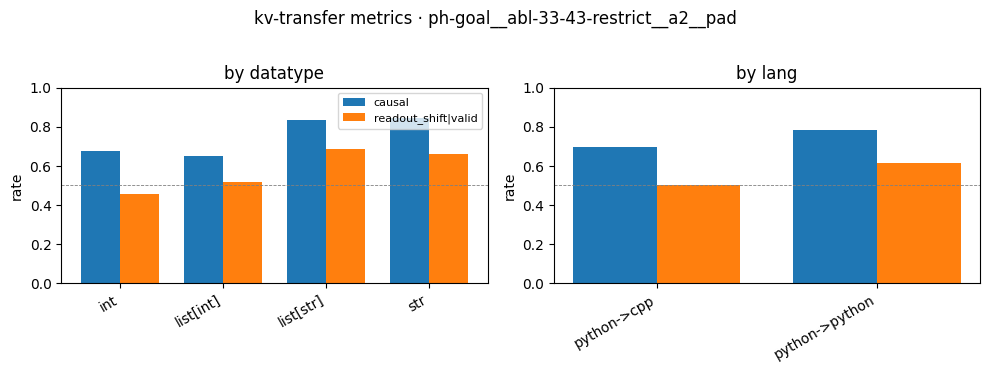

In [5]:
METRICS = [("causal", "causal_triggered_f", None),
           ("readout_shift|valid", "readout_shifted_f", "valid")]

def _rate(frame, col, restrict):
    f = frame[frame.readout_valid == True] if restrict == "valid" else frame
    s = f[col].dropna()
    return s.mean() if len(s) else np.nan

axes_to_plot = [a for a in ["datatype", "lang", "naming", "setup"] if sub[a].nunique() > 1]
fig, axarr = plt.subplots(1, len(axes_to_plot), figsize=(5 * len(axes_to_plot), 3.6), squeeze=False)
for ax, axis in zip(axarr[0], axes_to_plot):
    cats = sorted(sub[axis].dropna().unique())
    x = np.arange(len(cats)); w = 0.38
    for i, (label, col, restrict) in enumerate(METRICS):
        vals = [_rate(sub[sub[axis] == c], col, restrict) for c in cats]
        ax.bar(x + (i - 0.5) * w, vals, w, label=label)
    ax.set_xticks(x); ax.set_xticklabels(cats, rotation=30, ha="right")
    ax.set_ylim(0, 1); ax.axhline(0.5, color="grey", lw=0.6, ls="--")
    ax.set_title(f"by {axis}"); ax.set_ylabel("rate")
axarr[0][0].legend(fontsize=8, loc="upper right")
fig.suptitle(f"kv-transfer metrics · {RUN_TAG}", y=1.02)
plt.tight_layout(); plt.show()

## Ablation comparison — does the strategy (`zero` vs `restrict`) matter?

The run_tag axis is the intervention experiment. Compare causal / readout-shift across ablation strategies (and any alpha/align variants), matched on the shared configs.

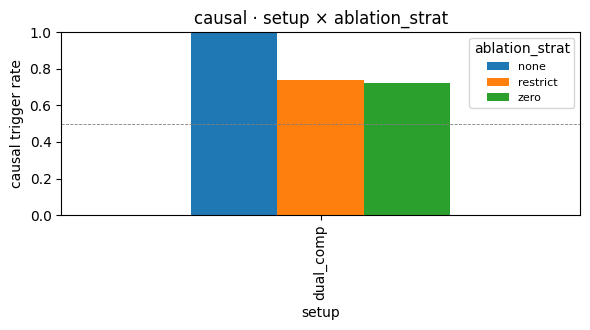

In [6]:
cmp = summary(df, ["setup", "knob_ablation_strat", "knob_ablate", "knob_alpha"])
display(cmp.style.format({"n": "{:.0f}", "causal": "{:.1%}",
        "readout_valid": "{:.1%}", "readout_shift|valid": "{:.1%}"}, na_rep="—"))

# side-by-side bars: causal per (setup, ablation_strat)
piv = df.groupby(["setup", "knob_ablation_strat"]).causal_triggered_f.mean().unstack()
if piv.shape[1] > 1:
    ax = piv.plot(kind="bar", figsize=(6, 3.4), ylim=(0, 1))
    ax.set_ylabel("causal trigger rate"); ax.set_title("causal · setup × ablation_strat")
    ax.axhline(0.5, color="grey", lw=0.6, ls="--"); ax.legend(title="ablation_strat", fontsize=8)
    plt.tight_layout(); plt.show()

## Where does it fail? — patched-readout label distribution (valid cases)

Among cases where the clean readouts landed correctly, what does the **patched** readout say? `dst` = intervention didn't move the readout; `neither` = readout became incoherent; `src`/`both` = shifted. High `dst`/`neither` explains a low shift rate.

In [7]:
v = sub[sub.readout_valid == True]
print(f"patched-readout labels among {len(v)} valid cases (run_tag={RUN_TAG}):")
display(v.groupby("setup").ro_patched.value_counts().unstack(fill_value=0))

# causal label distribution among ALL (incl. invalid) — 'neither' means hybrid/incoherent gen
print("causal labels by setup:")
display(sub.groupby("setup").causal_label.value_counts().unstack(fill_value=0))

patched-readout labels among 423 valid cases (run_tag=ph-goal__abl-33-43-restrict__a2__pad):


ro_patched,both,dst,neither,src
setup,,,,
dual_comp,9,148,39,227


causal labels by setup:


causal_label,both,dst,neither,src
setup,,,,
dual_comp,3,90,27,328


## Agreement — causal vs readout-shift

Do the two signals co-occur on the same instances? (readout may shift internally even when the generation doesn't follow — the dissociation we saw in q-transfer.)

In [8]:
sig = sub.dropna(subset=["causal_triggered", "readout_shifted"])
if len(sig):
    print(f"n={len(sig)}  ({RUN_TAG})")
    display(pd.crosstab(sig.causal_triggered, sig.readout_shifted,
                        rownames=["causal"], colnames=["readout_shifted"]))

n=448  (ph-goal__abl-33-43-restrict__a2__pad)


readout_shifted,False,True
causal,,
False,95,22
True,107,224


## Config-level table (recomputed live; flags still-running configs)

In [9]:
cfg = df.groupby(["setup", "run_tag", "config"]).agg(
    n=("causal_triggered", "size"),
    causal=("causal_triggered_f", "mean"),
    ro_valid=("readout_valid_f", "mean"),
    has_meta=("config_has_meta", "first")).reset_index()
cfg["ro_shift|valid"] = df[df.readout_valid == True].groupby(
    ["setup", "run_tag", "config"]).readout_shifted_f.mean().reindex(
    cfg.set_index(["setup", "run_tag", "config"]).index).values
print(f"{len(cfg)} configs · {(~cfg.has_meta).sum()} still running (no meta.json yet)")
display(cfg.sort_values(["setup", "run_tag", "config"]).style.format(
    {"causal": "{:.0%}", "ro_valid": "{:.0%}", "ro_shift|valid": "{:.0%}", "n": "{:.0f}"}, na_rep="—"))

17 configs · 0 still running (no meta.json yet)


,setup,run_tag,config,n,causal,ro_valid,has_meta,ro_shift|valid
0,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,int__desc__python-cpp,80,61%,91%,True,38%
1,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,int__desc__python-python,80,74%,99%,True,52%
2,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,list_int__desc__python-cpp,50,60%,100%,True,50%
3,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,list_int__desc__python-python,50,70%,100%,True,54%
4,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,list_str__desc__python-cpp,46,83%,96%,True,64%
5,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,list_str__desc__python-python,46,85%,91%,True,74%
6,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,str__desc__python-cpp,48,81%,90%,True,56%
7,dual_comp,ph-goal__abl-33-43-restrict__a2__pad,str__desc__python-python,48,88%,88%,True,76%
8,dual_comp,ph-goal__abl-33-43-zero__a2__pad,int__desc__python-cpp,80,61%,91%,True,40%
9,dual_comp,ph-goal__abl-33-43-zero__a2__pad,int__desc__python-python,80,70%,99%,True,51%


## Qualitative — inspect a few instances

In [10]:
def show_instance(row):
    print(f"[{row.setup} · {row.config} · {row.run_tag}]")
    print(f"  SRC target = {row.expected_next!r} ({row.expected_next_desc})")
    print(f"  DST frontier = {row.dst_next!r} ({row.dst_next_desc})")
    print(f"  causal={row.causal_label} triggered={row.causal_triggered} | "
          f"readout {row.ro_source}->{row.ro_dest}->{row.ro_patched} "
          f"(valid={row.readout_valid}, shifted={row.readout_shifted})")
    print(f"  patched gen : {row.gen_patched[:120]!r}")
    print(f"  readout src : {row.ro_src_txt[:80]!r}")
    print(f"  readout pat : {row.ro_pat_txt[:80]!r}")
    print("-" * 100)

# a couple of HITs and a couple of misses from the chosen run
for _, r in sub[sub.causal_triggered == True].head(2).iterrows():
    show_instance(r)
for _, r in sub[sub.causal_triggered == False].head(2).iterrows():
    show_instance(r)

[dual_comp · int__desc__python-cpp · ph-goal__abl-33-43-restrict__a2__pad]
  SRC target = 'count_even_digits' (the number of even digits)
  DST frontier = 'is_ascending' (returns true if the digits are in non-decreasing order)
  causal=src triggered=True | readout src->dst->dst (valid=True, shifted=False)
  patched gen : ' for (size_t i = 0; i < digits.size() - 1; ++i) {\n        if (digits[i] % 2 != 0) return false;\n    }\n    return true;\n}'
  readout src : 'Counting variables that are even.'
  readout pat : "I'm checking if the current digit is less than or equal to the next digit."
----------------------------------------------------------------------------------------------------
[dual_comp · int__desc__python-cpp · ph-goal__abl-33-43-restrict__a2__pad]
  SRC target = 'is_perfect' (returns true if the number equals the sum of its proper divisors)
  DST frontier = 'count_divisors' (the number of positive divisors of the number)
  causal=src triggered=True | readout src->dst->src 